In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Experimental-style simulation dataset
data = {
    "Voltage_V": [0.499, 1.500, 2.498, 3.500, 4.501],
    "Glucose_equiv_mM": [0.000, 2.501, 4.994, 7.499, 10.000]
}

# Create a Pandas DataFrame
df = pd.DataFrame(data)

# Display the dataset
print(df)


   Voltage_V  Glucose_equiv_mM
0      0.499             0.000
1      1.500             2.501
2      2.498             4.994
3      3.500             7.499
4      4.501            10.000


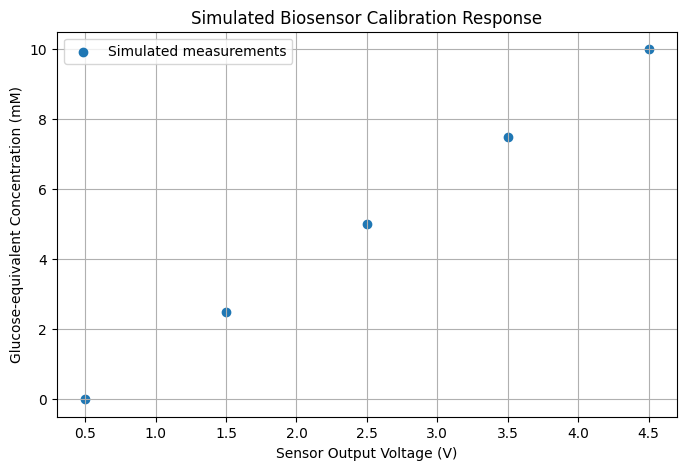

In [ ]:

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Voltage_V"],
    df["Glucose_equiv_mM"],
    marker="o",
    label="Simulated measurements"
)

plt.xlabel("Sensor Output Voltage (V)")
plt.ylabel("Glucose-equivalent Concentration (mM)")

plt.title("Simulated Biosensor Calibration Response")

plt.grid(True)
plt.legend()

plt.show()


In [ ]:

# Linear regression using NumPy

x = df["Voltage_V"].values
y = df["Glucose_equiv_mM"].values

# Calculate the slope and intercept
slope, intercept = np.polyfit(x, y, 1)

# Predict concentration using the regression model
y_pred = slope * x + intercept

# Calculate R-squared
ss_res = np.sum((y - y_pred) ** 2)
ss_tot = np.sum((y - np.mean(y)) ** 2)

r_squared = 1 - (ss_res / ss_tot)

print("Regression Results")
print("------------------")
print(f"Slope: {slope:.4f} mM/V")
print(f"Intercept: {intercept:.4f} mM")
print(f"R-squared: {r_squared:.6f}")


Regression Results
------------------
Slope: 2.4988 mM/V
Intercept: -1.2472 mM
R-squared: 1.000000


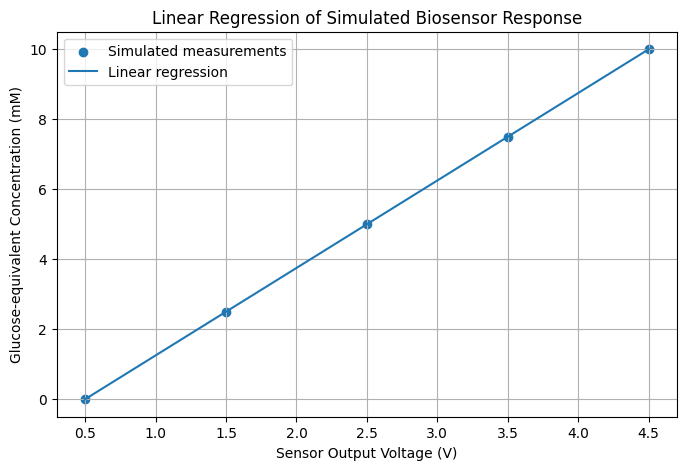

In [ ]:

plt.figure(figsize=(8, 5))

# Original measurements
plt.scatter(x, y, label="Simulated measurements")

# Regression line
plt.plot(
    x,
    y_pred,
    label="Linear regression"
)

plt.xlabel("Sensor Output Voltage (V)")
plt.ylabel("Glucose-equivalent Concentration (mM)")

plt.title("Linear Regression of Simulated Biosensor Response")

plt.grid(True)
plt.legend()

plt.show()


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Make the simulation reproducible
np.random.seed(42)

# Generate 200 sensor measurements
n_samples = 200

# Assume a constant underlying sensor output
true_voltage = 2.5

# Set the standard deviation of simulated noise
noise_std = 0.05

# Generate measurement noise
noise = np.random.normal(
    loc=0,
    scale=noise_std,
    size=n_samples
)

# Generate noisy sensor readings
raw_voltage = true_voltage + noise

# Keep voltage within the 0-5 V supply range
raw_voltage = np.clip(raw_voltage, 0, 5)

# Convert voltage into concentration-equivalent values
raw_glucose = np.clip(
    (raw_voltage - 0.5) * 2.5,
    0,
    10
)

# Create a dataset
noise_df = pd.DataFrame({
    "Sample": np.arange(1, n_samples + 1),
    "Voltage_V": raw_voltage,
    "Glucose_equiv_mM": raw_glucose
})

# Display the first 10 readings
print(noise_df.head(10))

# Display statistical information
print("\nSignal Statistics")
print("-----------------")
print(f"Mean voltage: {np.mean(raw_voltage):.4f} V")
print(f"Voltage standard deviation: {np.std(raw_voltage):.4f} V")


   Sample  Voltage_V  Glucose_equiv_mM
0       1   2.524836          5.062089
1       2   2.493087          4.982717
2       3   2.532384          5.080961
3       4   2.576151          5.190379
4       5   2.488292          4.970731
5       6   2.488293          4.970733
6       7   2.578961          5.197402
7       8   2.538372          5.095929
8       9   2.476526          4.941316
9      10   2.527128          5.067820

Signal Statistics
-----------------
Mean voltage: 2.4980 V
Voltage standard deviation: 0.0464 V


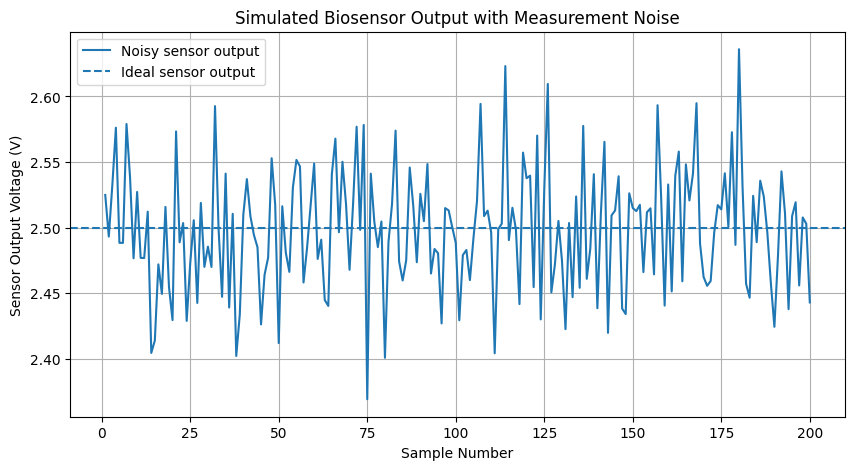

In [ ]:

plt.figure(figsize=(10, 5))

plt.plot(
    noise_df["Sample"],
    noise_df["Voltage_V"],
    label="Noisy sensor output"
)

plt.axhline(
    y=true_voltage,
    linestyle="--",
    label="Ideal sensor output"
)

plt.xlabel("Sample Number")
plt.ylabel("Sensor Output Voltage (V)")

plt.title("Simulated Biosensor Output with Measurement Noise")

plt.grid(True)
plt.legend()

plt.show()


In [ ]:

# Apply a moving average filter

window_size = 5

noise_df["Filtered_V"] = (
    noise_df["Voltage_V"]
    .rolling(window=window_size, center=True)
    .mean()
)

# Remove rows where the rolling window is incomplete
valid_data = noise_df.dropna(subset=["Filtered_V"])

print(valid_data.head(10))


    Sample  Voltage_V  Glucose_equiv_mM  Filtered_V
2        3   2.532384          5.080961    2.522950
3        4   2.576151          5.190379    2.515642
4        5   2.488292          4.970731    2.532816
5        6   2.488293          4.970733    2.534014
6        7   2.578961          5.197402    2.514089
7        8   2.538372          5.095929    2.521856
8        9   2.476526          4.941316    2.519563
9       10   2.527128          5.067820    2.499114
10      11   2.476829          4.942073    2.493859
11      12   2.476714          4.941784    2.479421


In [ ]:

# Apply a moving average filter

window_size = 5

noise_df["Filtered_V"] = (
    noise_df["Voltage_V"]
    .rolling(window=window_size, center=True)
    .mean()
)

# Remove rows where the rolling window is incomplete
valid_data = noise_df.dropna(subset=["Filtered_V"])

print(valid_data.head(10))


    Sample  Voltage_V  Glucose_equiv_mM  Filtered_V
2        3   2.532384          5.080961    2.522950
3        4   2.576151          5.190379    2.515642
4        5   2.488292          4.970731    2.532816
5        6   2.488293          4.970733    2.534014
6        7   2.578961          5.197402    2.514089
7        8   2.538372          5.095929    2.521856
8        9   2.476526          4.941316    2.519563
9       10   2.527128          5.067820    2.499114
10      11   2.476829          4.942073    2.493859
11      12   2.476714          4.941784    2.479421


In [ ]:

# Compare both signals over the same valid samples

raw_std = valid_data["Voltage_V"].std(ddof=0)
filtered_std = valid_data["Filtered_V"].std(ddof=0)

reduction = (1 - filtered_std / raw_std) * 100

print("Signal Processing Results")
print("-------------------------")

print(f"Raw signal standard deviation: {raw_std:.5f} V")
print(f"Filtered signal standard deviation: {filtered_std:.5f} V")

print(f"Reduction in standard deviation: {reduction:.2f}%")


Signal Processing Results
-------------------------
Raw signal standard deviation: 0.04670 V
Filtered signal standard deviation: 0.01885 V
Reduction in standard deviation: 59.63%


In [ ]:

import pandas as pd
from io import StringIO
import numpy as np

# Paste your copied Serial Monitor readings here.
csv_data = """
Noisy_ADC,Filtered_ADC,Voltage_V,Glucose_mM
542,535.40,2.617,5.292
551,540.60,2.642,5.356
535,542.20,2.650,5.375
526,538.40,2.631,5.329
515,533.80,2.609,5.272
524,530.20,2.591,5.228
522,524.40,2.563,5.158
552,527.80,2.580,5.199
534,529.40,2.587,5.219
525,531.40,2.597,5.243
544,535.40,2.617,5.292
534,537.80,2.629,5.321
549,537.20,2.626,5.314
521,534.60,2.613,5.282
514,532.40,2.602,5.255
533,530.20,2.591,5.228
532,529.80,2.589,5.224
519,523.80,2.560,5.150
532,526.00,2.571,5.177
546,532.40,2.602,5.255
525,530.80,2.594,5.236
515,527.40,2.578,5.194
521,527.80,2.580,5.199
514,524.20,2.562,5.155
518,518.60,2.535,5.087
522,518.00,2.532,5.079
550,525.00,2.566,5.165
517,524.20,2.562,5.155
529,527.20,2.577,5.192
513,526.20,2.572,5.180
531,528.00,2.581,5.202
548,527.60,2.579,5.197
538,531.80,2.599,5.248
545,535.00,2.615,5.287
534,539.20,2.635,5.338
551,543.20,2.655,5.387
518,537.20,2.626,5.314
523,534.20,2.611,5.277
518,528.80,2.585,5.211
550,532.00,2.600,5.250
552,532.20,2.601,5.253
"""

# Load the measurements
measured_df = pd.read_csv(StringIO(csv_data))

# Remove the first 10 samples to avoid initialization effects
measured_df = measured_df.iloc[10:].reset_index(drop=True)

# Calculate standard deviations
raw_std = measured_df["Noisy_ADC"].std(ddof=0)
filtered_std = measured_df["Filtered_ADC"].std(ddof=0)

# Calculate standard deviation reduction
reduction = (1 - filtered_std / raw_std) * 100

print("Arduino Signal Processing Analysis")
print("----------------------------------")
print(f"Raw ADC standard deviation: {raw_std:.3f}")
print(f"Filtered ADC standard deviation: {filtered_std:.3f}")
print(f"Noise reduction: {reduction:.2f}%")


Arduino Signal Processing Analysis
----------------------------------
Raw ADC standard deviation: 12.987
Filtered ADC standard deviation: 5.692
Noise reduction: 56.17%


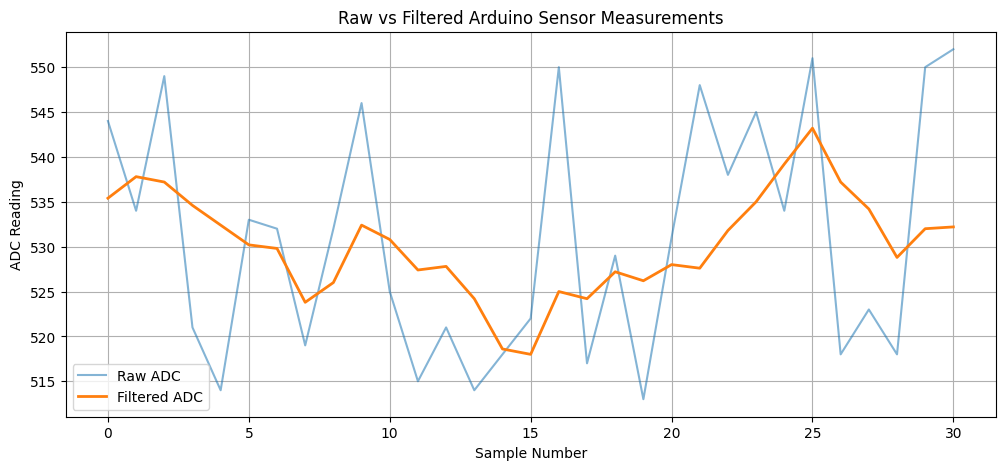

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    measured_df.index,
    measured_df["Noisy_ADC"],
    label="Raw ADC",
    alpha=0.55
)

plt.plot(
    measured_df.index,
    measured_df["Filtered_ADC"],
    label="Filtered ADC",
    linewidth=2
)

plt.xlabel("Sample Number")
plt.ylabel("ADC Reading")

plt.title("Raw vs Filtered Arduino Sensor Measurements")

plt.grid(True)
plt.legend()

plt.show()


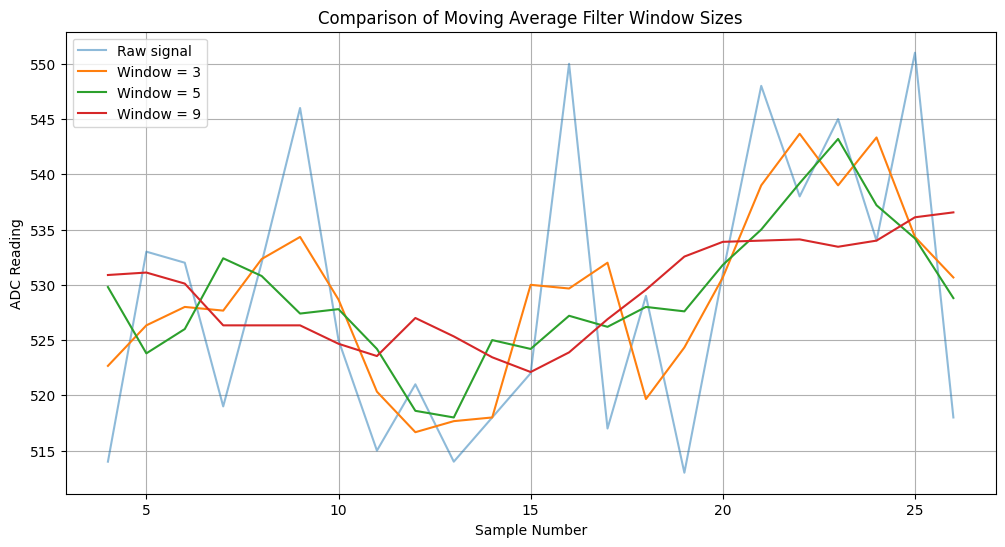

   Window Size  Filtered Std  Reduction (%)
0            3         7.633         38.051
1            5         5.915         51.998
2            9         4.396         64.319


In [ ]:

# Compare different moving average window sizes

raw_signal = measured_df["Noisy_ADC"].astype(float)

window_sizes = [3, 5, 9]

# Use the same sample positions for a fair comparison
trim = max(window_sizes) // 2

raw_common = raw_signal.iloc[trim:-trim]

results = []

plt.figure(figsize=(12, 6))

plt.plot(
    raw_common.index,
    raw_common,
    label="Raw signal",
    alpha=0.5
)

for window in window_sizes:

    filtered = (
        raw_signal
        .rolling(window=window, center=True)
        .mean()
        .iloc[trim:-trim]
    )

    raw_std = raw_common.std(ddof=0)
    filtered_std = filtered.std(ddof=0)

    reduction = (1 - filtered_std / raw_std) * 100

    results.append({
        "Window Size": window,
        "Filtered Std": filtered_std,
        "Reduction (%)": reduction
    })

    plt.plot(
        raw_common.index,
        filtered,
        label=f"Window = {window}"
    )

plt.xlabel("Sample Number")
plt.ylabel("ADC Reading")
plt.title("Comparison of Moving Average Filter Window Sizes")

plt.grid(True)
plt.legend()
plt.show()

# Display numerical comparison
results_df = pd.DataFrame(results)
print(results_df.round(3))
